# Detecção e Predição de Enchentes — Bacia do Tamanduateí
### Modelos interpretáveis: Regressão Logística e Árvore de Decisão

Notebook organizado: construção do painel célula × dia (grade + INMET + histórico de alagamentos), análise exploratória e os dois modelos interpretáveis otimizados (F1-score como métrica principal).

# 1. Preparação do Ambiente e Descompactação dos Dados
Nesta etapa, importamos as bibliotecas necessárias para manipulação de dados em tabelas (Pandas) e dados espaciais (GeoPandas). Em seguida, descompactamos o repositório oficial que contém o shapefile da grade e a planilha de alagamentos.

In [ ]:
# Instalar a biblioteca espacial (caso o Colab não a tenha por padrão)
!pip install geopandas

import zipfile
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

# Descompactar o arquivo ZIP
zip_path = "floods_saopaulo-main.zip"
extract_dir = "/content/floods_data"

with zipfile.ZipFile(zip_path, 'r') as z:
    z.extractall(extract_dir)

print("Arquivos descompactados com sucesso!")

Arquivos descompactados com sucesso!


# 2. Processamento dos Dados Meteorológicos (INMET)
Além da chuva diária, agora agregamos por dia diversas variáveis horárias do INMET que
têm relação física com enchentes: pico de intensidade da chuva em 1h, nº de horas de
chuva, chuva no período convectivo da tarde/noite, pressão mínima e amplitude de pressão,
umidade, temperatura (máxima e amplitude), rajada de vento e radiação global. As janelas
deslizantes de saturação do solo (3 e 7 dias) são calculadas antes de filtrar os dias secos.


In [ ]:
# ---- Carregar INMET ----
inmet_file = "INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2019_A_31-12-2019.CSV"
df_inmet = pd.read_csv(inmet_file, sep=';', encoding='latin-1', skiprows=8, decimal=',')
df_inmet['Data'] = pd.to_datetime(df_inmet['Data'])

# Localiza colunas por palavra-chave (robusto a acentos/símbolos no cabeçalho)
def col(chave):
    for c in df_inmet.columns:
        if chave.lower() in c.lower():
            return c
    return None

col_chuva   = col('PRECIPITA')
col_pressao = col('PRESSAO ATMOSFERICA AO NIVEL')
col_rad     = col('RADIACAO GLOBAL')
col_temp    = col('TEMPERATURA DO AR - BULBO SECO')
col_orv     = col('TEMPERATURA DO PONTO DE ORVALHO')
col_umid    = col('UMIDADE RELATIVA DO AR, HORARIA')
col_raj     = col('VENTO, RAJADA MAXIMA')
col_vel     = col('VENTO, VELOCIDADE HORARIA')

df_inmet[col_chuva] = df_inmet[col_chuva].fillna(0)

# Hora local (SP = UTC-3) para isolar a janela convectiva da tarde/noite
df_inmet['hora_utc']   = df_inmet['Hora UTC'].astype(str).str.extract(r'(\d{2})').astype(int)
df_inmet['hora_local'] = (df_inmet['hora_utc'] - 3) % 24

g = df_inmet.groupby('Data')

df_clima = pd.DataFrame({
    'chuva_dia'    : g[col_chuva].sum(),                       # total diário
    'chuva_max_h'  : g[col_chuva].max(),                       # pico de intensidade em 1h
    'horas_chuva'  : g[col_chuva].apply(lambda s: (s > 0).sum()),
    'pressao_min'  : g[col_pressao].min(),
    'pressao_amp'  : g[col_pressao].max() - g[col_pressao].min(),
    'umidade_med'  : g[col_umid].mean(),
    'umidade_max'  : g[col_umid].max(),
    'temp_med'     : g[col_temp].mean(),
    'temp_max'     : g[col_temp].max(),
    'temp_amp'     : g[col_temp].max() - g[col_temp].min(),
    'orvalho_med'  : g[col_orv].mean(),
    'rajada_max'   : g[col_raj].max(),
    'vento_med'    : g[col_vel].mean(),
    'radiacao_sum' : g[col_rad].sum(),
}).reset_index()

# Chuva da tarde/noite (12h–23h local): janela convectiva típica de São Paulo
chuva_tarde = (df_inmet[df_inmet['hora_local'].between(12, 23)]
               .groupby('Data')[col_chuva].sum()
               .rename('chuva_tarde'))
df_clima = df_clima.merge(chuva_tarde, on='Data', how='left')

# Janelas de saturação do solo (ANTES de filtrar dias secos)
df_clima = df_clima.sort_values('Data').reset_index(drop=True)
df_clima['chuva_acum_3d'] = df_clima['chuva_dia'].rolling(window=3, min_periods=1).sum()
df_clima['chuva_acum_7d'] = df_clima['chuva_dia'].rolling(window=7, min_periods=1).sum()

# Preenche eventuais faltantes (radiação à noite, etc.) e filtra só dias com chuva
df_clima = df_clima.fillna(df_clima.median(numeric_only=True))
df_clima = df_clima[df_clima['chuva_dia'] > 0]

print(f"Dias com chuva em 2019: {len(df_clima)}")
print(f"Variáveis meteorológicas criadas: {[c for c in df_clima.columns if c != 'Data']}")
df_clima.head()


Dias com chuva em 2019: 151
Variáveis meteorológicas criadas: ['chuva_dia', 'chuva_max_h', 'horas_chuva', 'pressao_min', 'pressao_amp', 'umidade_med', 'umidade_max', 'temp_med', 'temp_max', 'temp_amp', 'orvalho_med', 'rajada_max', 'vento_med', 'radiacao_sum', 'chuva_tarde', 'chuva_acum_3d', 'chuva_acum_7d']


,Data,chuva_dia,chuva_max_h,horas_chuva,pressao_min,pressao_amp,umidade_med,umidade_max,temp_med,temp_max,temp_amp,orvalho_med,rajada_max,vento_med,radiacao_sum,chuva_tarde,chuva_acum_3d,chuva_acum_7d
0,2019-01-01,6.6,2.4,5,924.0,3.6,70.541667,87,23.795833,30.9,10.2,17.704167,9.3,1.870833,21230.0,6.6,6.6,6.6
2,2019-01-03,31.0,18.0,5,922.3,4.4,61.958333,88,26.387500,32.8,11.9,18.187500,13.5,2.704167,22166.2,31.0,37.6,37.6
3,2019-01-04,15.8,8.6,7,923.2,3.2,75.000000,88,23.341667,28.3,6.8,18.520833,11.4,2.533333,17466.2,15.8,46.8,53.4
4,2019-01-05,17.6,4.8,7,923.9,2.9,80.250000,87,21.887500,24.6,4.3,18.304167,8.5,2.220833,10633.6,6.6,64.4,71.0
5,2019-01-06,33.8,14.6,6,923.4,3.6,74.208333,90,23.570833,28.9,8.7,18.241667,8.3,1.362500,20024.5,23.4,67.2,104.8


# 3. Processamento da Grade Espacial e Histórico de Enchentes
Nesta célula, carregamos o Shapefile que divide São Paulo em 3.087 células e selecionamos apenas os atributos estáticos relevantes. Depois, fazemos um Cruzamento Espacial (Spatial Join) com os pontos exatos de onde ocorreram as enchentes para descobrir em qual célula cada uma caiu.

In [ ]:
# 1. Carregar a Grade Espacial
grid_path = "/content/floods_data/floods_saopaulo-main/3_output/GRID_product.shp"
grid = gpd.read_file(grid_path)

# Filtrar apenas os atributos estáticos que vamos usar no modelo (Opção B)
colunas_manter = ['GRID_ID', 'Population', 'Workplaces', 'Education', 'Vuln_Clas', 'HAND_minim',
                  'Workers', 'Students', 'People_sum', 'Vulner_max', 'HAND_clas', 'Exp__class',
                  'geometry']

grid = grid[colunas_manter]

# 2. Carregar o Histórico de Alagamentos (A "Verdade Terrestre")
floods_path = "/content/floods_data/floods_saopaulo-main/1_input/e_Floods_2019.xlsx"
df_floods = pd.read_excel(floods_path)

# Padronizar a data (remover horas se houver)
df_floods['DATE'] = pd.to_datetime(df_floods['DATE']).dt.normalize()

# Converter o Excel de alagamentos em um GeoDataFrame
# CORREÇÃO APLICADA AQUI: Definindo o CRS inicial correto (UTM SIRGAS 2000 Zona 23S)
gdf_floods = gpd.GeoDataFrame(
    df_floods,
    geometry=gpd.points_from_xy(df_floods.X, df_floods.Y),
    crs="EPSG:31983"
)

# Garantir que ambos os mapas estão na mesma "língua matemática" antes de cruzar
gdf_floods = gdf_floods.to_crs(grid.crs)

# Cruzamento Espacial: Descobre em qual célula (GRID_ID) cada ponto de alagamento caiu
floods_grid = gpd.sjoin(gdf_floods, grid, how="inner", predicate="intersects")

# Criamos uma tabela só com a Data e o GRID_ID de onde alagou
floods_target = floods_grid[['DATE', 'GRID_ID']].drop_duplicates()
floods_target['alagou'] = 1

print(f"Total de enchentes mapeadas em células: {len(floods_target)}")

Total de enchentes mapeadas em células: 250


# 4. A Base Final (O Grande Merge)
Agora, construímos a base tabular final. Primeiro criamos todas as combinações possíveis entre os dias de chuva e as células da grade. Depois, anexamos a chuva daquele dia, os atributos daquela célula e verificamos se há um registro de enchente para aquele par (Célula, Data).

In [ ]:
# Criar todas as combinações de Células vs Dias com Chuva
celulas = grid['GRID_ID'].unique()
dias_chuva = df_clima['Data'].unique()
combinacoes = list(itertools.product(celulas, dias_chuva))

# Criar o DataFrame base
df_final = pd.DataFrame(combinacoes, columns=['GRID_ID', 'Data'])

# 1. Trazer os atributos físicos de cada célula
df_final = df_final.merge(grid.drop(columns='geometry'), on='GRID_ID', how='left')

# 2. Trazer os dados de chuva de cada data
df_final = df_final.merge(df_clima, on='Data', how='left')

# 3. Trazer o Alvo (Target): Marcar 1 se alagou, 0 se não alagou
df_final = df_final.merge(floods_target, left_on=['GRID_ID', 'Data'], right_on=['GRID_ID', 'DATE'], how='left')
df_final['alagou'] = df_final['alagou'].fillna(0).astype(int)

# Limpeza final
df_final = df_final.drop(columns=['DATE'])
df_final = df_final.dropna() # Remover possíveis valores nulos

print(f"Dimensões do Dataset Final: {df_final.shape[0]} linhas e {df_final.shape[1]} colunas.")
df_final.head()

Dimensões do Dataset Final: 466137 linhas e 31 colunas.


,GRID_ID,Data,Population,Workplaces,Education,Vuln_Clas,HAND_minim,Workers,Students,People_sum,...,temp_max,temp_amp,orvalho_med,rajada_max,vento_med,radiacao_sum,chuva_tarde,chuva_acum_3d,chuva_acum_7d,alagou
0,200ME57538N86992,2019-01-01,681,15,0,1,59,5110.79795,0.0,5791.79795,...,30.9,10.2,17.704167,9.3,1.870833,21230.0,6.6,6.6,6.6,0
1,200ME57538N86992,2019-01-03,681,15,0,1,59,5110.79795,0.0,5791.79795,...,32.8,11.9,18.187500,13.5,2.704167,22166.2,31.0,37.6,37.6,0
2,200ME57538N86992,2019-01-04,681,15,0,1,59,5110.79795,0.0,5791.79795,...,28.3,6.8,18.520833,11.4,2.533333,17466.2,15.8,46.8,53.4,0
3,200ME57538N86992,2019-01-05,681,15,0,1,59,5110.79795,0.0,5791.79795,...,24.6,4.3,18.304167,8.5,2.220833,10633.6,6.6,64.4,71.0,0
4,200ME57538N86992,2019-01-06,681,15,0,1,59,5110.79795,0.0,5791.79795,...,28.9,8.7,18.241667,8.3,1.362500,20024.5,23.4,67.2,104.8,0


# 5. Resultados Preliminares: Análise Exploratória (EDA)
Este é o conteúdo principal para o relatório parcial. Vamos gerar o gráfico de desbalanceamento de classes para justificar o uso do "class weights" na metodologia e uma matriz de correlação das variáveis.

/tmp/ipykernel_1200/640846425.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df_final, x='alagou', palette='viridis')


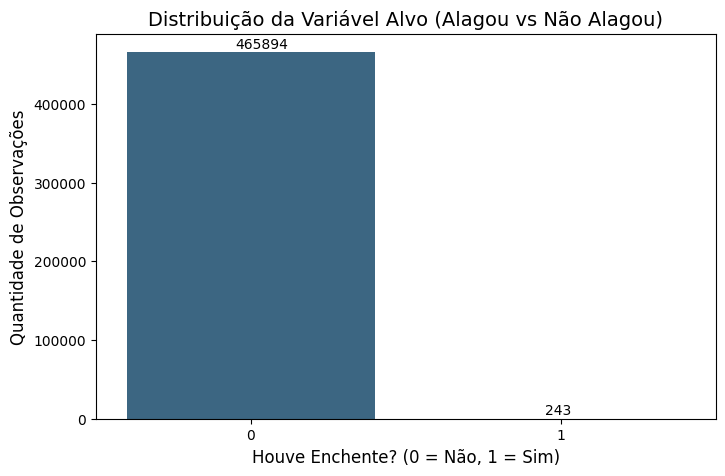

--------------------------------------------------


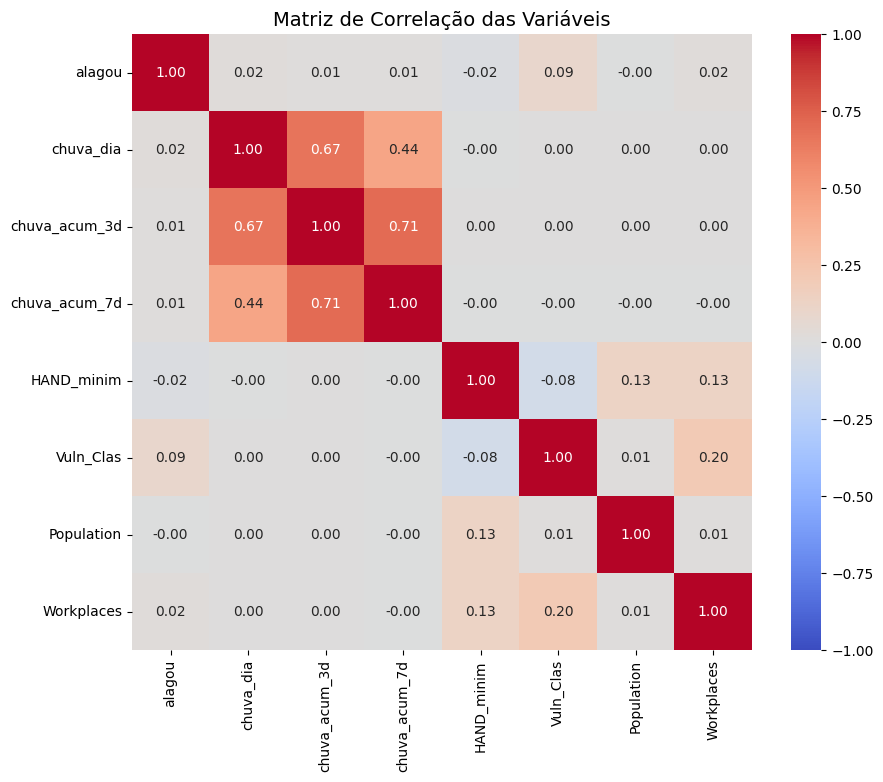

In [ ]:
# 1. Gráfico de Desbalanceamento
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_final, x='alagou', palette='viridis')
plt.title('Distribuição da Variável Alvo (Alagou vs Não Alagou)', fontsize=14)
plt.xlabel('Houve Enchente? (0 = Não, 1 = Sim)', fontsize=12)
plt.ylabel('Quantidade de Observações', fontsize=12)

# Adicionar os números acima das barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + 0.35, p.get_height() + 5000))

plt.show()

print("-" * 50)

# 2. Matriz de Correlação
plt.figure(figsize=(10, 8))
colunas_correlacao = ['alagou', 'chuva_dia', 'chuva_acum_3d', 'chuva_acum_7d',
                      'HAND_minim', 'Vuln_Clas', 'Population', 'Workplaces']
correlacao = df_final[colunas_correlacao].corr()

sns.heatmap(correlacao, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Matriz de Correlação das Variáveis', fontsize=14)
plt.show()

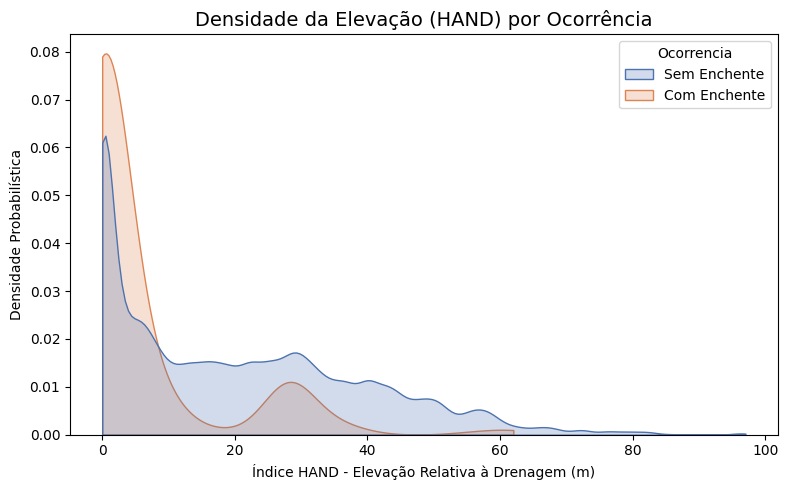

HAND com enchente: mediana=0.0 m | % <= 3 m: 74.9% | % > 20 m: 13.6%
HAND sem enchente: mediana=17.0 m


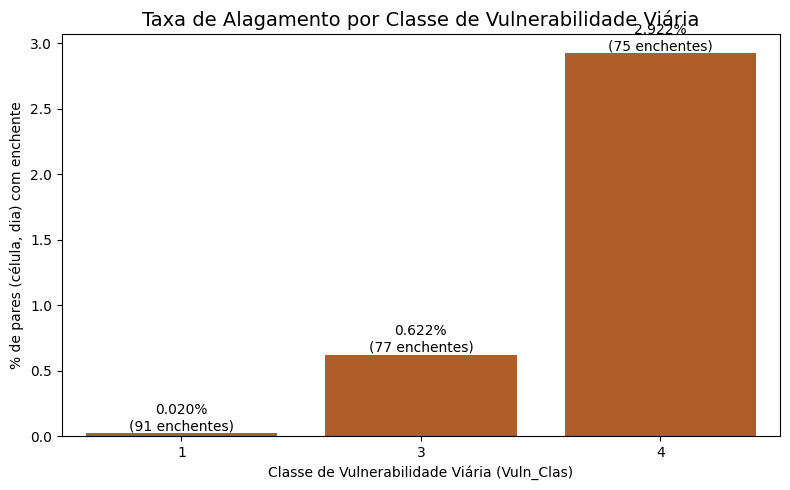

            pares  enchentes  % alagou
Vuln_Clas                             
1          451188         91  0.020169
3           12382         77  0.621870
4            2567         75  2.921698


In [ ]:
# Figuras 4 e 5 do relatório, geradas a partir do df_final real
import numpy as np

# Figura 4 — densidade do HAND por classe (eixo com a faixa completa, sem corte em 20 m)
plt.figure(figsize=(8, 5))
plot_df = df_final.assign(Ocorrencia=df_final['alagou'].map({0: 'Sem Enchente', 1: 'Com Enchente'}))
sns.kdeplot(data=plot_df, x='HAND_minim', hue='Ocorrencia', common_norm=False,
            fill=True, cut=0, palette={'Sem Enchente': '#4C72B0', 'Com Enchente': '#DD8452'})
plt.title('Densidade da Elevação (HAND) por Ocorrência', fontsize=14)
plt.xlabel('Índice HAND - Elevação Relativa à Drenagem (m)')
plt.ylabel('Densidade Probabilística')
plt.tight_layout(); plt.savefig('elevacao_x_enchente.png', dpi=150, bbox_inches='tight'); plt.show()

pos = df_final.loc[df_final['alagou'] == 1, 'HAND_minim']
neg = df_final.loc[df_final['alagou'] == 0, 'HAND_minim']
print(f"HAND com enchente: mediana={pos.median():.1f} m | % <= 3 m: {100*(pos<=3).mean():.1f}% | % > 20 m: {100*(pos>20).mean():.1f}%")
print(f"HAND sem enchente: mediana={neg.median():.1f} m")

# Figura 5 — Vuln_Clas é uma classe discreta (1, 3, 4): taxa de alagamento por classe
taxa = df_final.groupby('Vuln_Clas')['alagou'].agg(['mean', 'sum', 'size'])
taxa['pct'] = 100 * taxa['mean']
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=taxa.index.astype(str), y=taxa['pct'], color='#C55A11')
for i, (pct, n) in enumerate(zip(taxa['pct'], taxa['sum'])):
    ax.annotate(f'{pct:.3f}%\n({int(n)} enchentes)', (i, pct), ha='center', va='bottom')
plt.title('Taxa de Alagamento por Classe de Vulnerabilidade Viária', fontsize=14)
plt.xlabel('Classe de Vulnerabilidade Viária (Vuln_Clas)')
plt.ylabel('% de pares (célula, dia) com enchente')
plt.tight_layout(); plt.savefig('vulnerabilidade_viaria.png', dpi=150, bbox_inches='tight'); plt.show()
print(taxa[['size', 'sum', 'pct']].rename(columns={'size': 'pares', 'sum': 'enchentes', 'pct': '% alagou'}))


# 6. Regressão Logística (modelo otimizado)

Padronização + atributos de interação (chuva × HAND, chuva × vulnerabilidade, `log1p`), `GridSearchCV` e limiar via curva precisão–recall. F1 final por `cross_val_predict` (validação cruzada estratificada) sobre toda a base.

In [ ]:
import numpy as np, pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.metrics import precision_recall_curve, confusion_matrix

base = df_final.drop(columns=['GRID_ID','Data','alagou', 'Vuln_Clas']).select_dtypes(include=[np.number]).copy()
y = df_final['alagou'].values

eps = 1.0
if 'HAND_minim' in base:
    base['chuva_sobre_hand'] = base['chuva_dia'] / (base['HAND_minim'] + eps)
    if 'chuva_max_h' in base:
        base['chuvamax_sobre_hand'] = base['chuva_max_h'] / (base['HAND_minim'] + eps)
    base['hand_baixo'] = (base['HAND_minim'] < 3).astype(int)
if 'Vuln_Clas' in base and 'chuva_acum_3d' in base:
    base['chuva3d_x_vuln'] = base['chuva_acum_3d'] * base['Vuln_Clas']
for c in ['chuva_dia','chuva_max_h','chuva_acum_3d','chuva_acum_7d','radiacao_sum']:
    if c in base: base['log_'+c] = np.log1p(base[c].clip(lower=0))

X = base.values
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# subamostra só para a BUSCA de hiperparâmetros (acelera muito)
rng = np.random.RandomState(42)
pos = np.where(y==1)[0]; neg = np.where(y==0)[0]
idx = np.concatenate([pos, rng.choice(neg, size=min(len(neg),40000), replace=False)])

pipe = Pipeline([('sc', StandardScaler()),
                 ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, solver='liblinear'))])
grid = {'clf__penalty': ['l1','l2'], 'clf__C': [0.1, 1, 5]}
gs = GridSearchCV(pipe, grid, scoring='f1', cv=cv, n_jobs=-1)
gs.fit(X[idx], y[idx])
print("Melhores params LR:", gs.best_params_)

# F1 final: validação cruzada no conjunto COMPLETO com os melhores params
proba = cross_val_predict(gs.best_estimator_, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
prec, rec, thr = precision_recall_curve(y, proba)
f1 = 2*prec*rec/(prec+rec+1e-9); i = f1[:-1].argmax(); lim = thr[i]
cm = confusion_matrix(y, (proba>=lim).astype(int))
print(f"""
=== REGRESSÃO LOGÍSTICA (otimizada) ===""")
print(f"Limiar={lim:.3f} | Precisão={prec[i]:.4f} | Recall={rec[i]:.4f} | F1={f1[i]:.4f} | FP={cm[0,1]}")
print(cm)

Melhores params LR: {'clf__C': 5, 'clf__penalty': 'l2'}

=== REGRESSÃO LOGÍSTICA (otimizada) ===
Limiar=0.992 | Precisão=0.0101 | Recall=0.0782 | F1=0.0179 | FP=1862
[[464032   1862]
 [   224     19]]


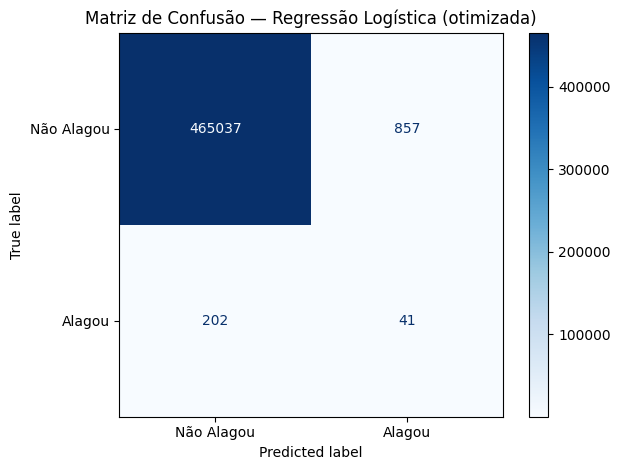

In [ ]:
# Figura da matriz de confusão (Regressão Logística otimizada) para o relatório
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm, display_labels=['Não Alagou', 'Alagou']).plot(
    cmap='Blues', values_format='d')
plt.title('Matriz de Confusão — Regressão Logística (otimizada)')
plt.tight_layout()
plt.savefig('matriz_confusao_regressao.png', dpi=150, bbox_inches='tight')
plt.show()

# 7. Árvore de Decisão (modelo otimizado)

Busca de `max_depth`, `min_samples_leaf` e `ccp_alpha` (poda por custo-complexidade) + limiar ótimo via OOF, mantendo a árvore interpretável.

In [ ]:
from sklearn.tree import DecisionTreeClassifier

X = df_final.drop(columns=['GRID_ID','Data','alagou', 'Vuln_Clas']).select_dtypes(include=[np.number]).values
y = df_final['alagou'].values
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

rng = np.random.RandomState(42)
pos = np.where(y==1)[0]; neg = np.where(y==0)[0]
idx = np.concatenate([pos, rng.choice(neg, size=min(len(neg),40000), replace=False)])

grid_dt = {'max_depth':[10, 16, None], 'min_samples_leaf':[5, 20, 50], 'ccp_alpha':[0.0, 1e-4]}
gs_dt = GridSearchCV(DecisionTreeClassifier(class_weight='balanced', random_state=42),
                     grid_dt, scoring='f1', cv=cv, n_jobs=-1)
gs_dt.fit(X[idx], y[idx])
print("Melhores params Árvore:", gs_dt.best_params_)

proba = cross_val_predict(gs_dt.best_estimator_, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:,1]
prec, rec, thr = precision_recall_curve(y, proba)
f1 = 2*prec*rec/(prec+rec+1e-9); i = f1[:-1].argmax(); lim = thr[i]
cm = confusion_matrix(y, (proba>=lim).astype(int))
print(f"""
=== ÁRVORE DE DECISÃO (otimizada) ===""")
print(f"Limiar={lim:.3f} | Precisão={prec[i]:.4f} | Recall={rec[i]:.4f} | F1={f1[i]:.4f} | FP={cm[0,1]}")
print(cm)

Melhores params Árvore: {'ccp_alpha': 0.0001, 'max_depth': None, 'min_samples_leaf': 5}

=== ÁRVORE DE DECISÃO (otimizada) ===
Limiar=0.992 | Precisão=0.0520 | Recall=0.3333 | F1=0.0900 | FP=1476
[[464418   1476]
 [   162     81]]


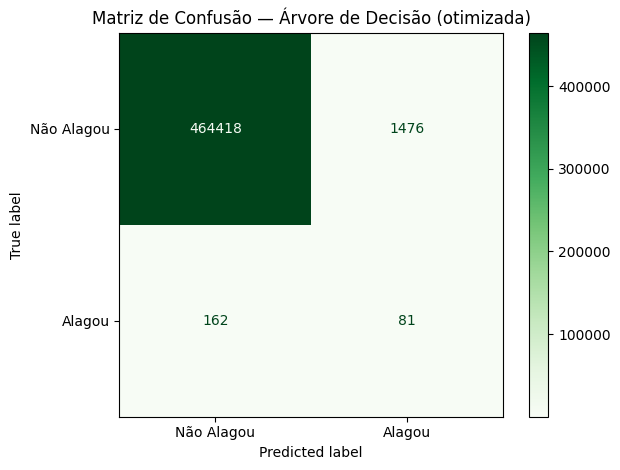

In [ ]:
# Figura da matriz de confusão (Árvore de Decisão otimizada) para o relatório
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay(cm, display_labels=['Não Alagou', 'Alagou']).plot(
    cmap='Greens', values_format='d')
plt.title('Matriz de Confusão — Árvore de Decisão (otimizada)')
plt.tight_layout()
plt.savefig('matriz_confusao_arvore.png', dpi=150, bbox_inches='tight')
plt.show()